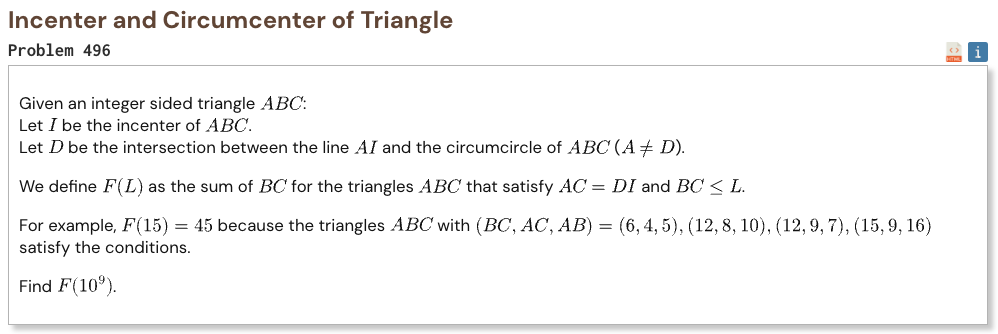

## Initial approach

- reduce the geometry condition to coprime integer pairs that generate all valid triangles
- each pair can be scaled several times while the base side stays below the limit
- sum all possible scaling factors at once instead of checking them separately
- use Möbius inclusion exclusion to sum only values coprime to the first parameter
- group consecutive values that give the same scaling limit
- only scan the first parameter up to the square root of the limit
- add all valid base sides to get the final result

In [1]:
%%time

from math import isqrt

L = 10**9
R = isqrt(L)

spf = list(range(R + 1))

for p in range(2, isqrt(R) + 1):
    if spf[p] == p:
        for x in range(p * p, R + 1, p):
            if spf[x] == x:
                spf[x] = p

def squarefree_terms(n):
    primes = []

    while n > 1:
        p = spf[n]
        primes.append(p)

        while n % p == 0:
            n //= p

    terms = [(1, 1)]

    for p in primes:
        old = terms[:]

        for d, sign in old:
            terms.append((d * p, -sign))

    return terms

def triangular(n):
    return n * (n + 1) // 2

result = 0

for r in range(1, R + 1):
    left = r + 1
    upper = min(2 * r - 1, L // r)

    if left > upper:
        continue

    terms = squarefree_terms(r)

    def coprime_sum(x):
        total = 0

        for d, sign in terms:
            q = x // d
            total += sign * d * triangular(q)

        return total

    s = left

    while s <= upper:
        scale = L // (r * s)
        end = min(upper, L // (r * scale))

        result += (
            r
            * triangular(scale)
            * (coprime_sum(end) - coprime_sum(s - 1))
        )

        s = end + 1

print("Result:", result)

Result: 2042473533769142717
CPU times: user 1.45 s, sys: 16.2 ms, total: 1.47 s
Wall time: 1.5 s
